## 1. Locate the project and SQL

Pathlib keeps file paths portable. Run this notebook from the project root or notebooks folder. SQL 19 supplies the first state-level exploration; SQL 20 supplies the later scoring inputs.

In [1]:
from pathlib import Path
import duckdb
import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

db_path = project_root / "data" / "olist.duckdb"
sql_path = project_root / "sql" / "19_state_rankings.sql"

print(db_path)
print(sql_path)

data/olist.duckdb
sql/19_state_rankings.sql


## 2. Run SQL through DuckDB

Read the saved query, open a read-only connection, and return a pandas DataFrame. Closing the connection releases the file handle. Avoid running another writable DuckDB connection at the same time.

In [2]:
query = sql_path.read_text(encoding="utf-8")

con = duckdb.connect(
    str(db_path),
    read_only=True
)

state_df = con.sql(query).df()

con.close()

state_df.head()

,state,delivered_orders,product_revenue,late_orders,late_delivery_rate_pct,sellers_in_state,orders_per_seller,demand_rank,delay_risk_rank,supply_gap_rank
0,SP,40399,5054516.95,2384.0,5.90,1849,21.85,1,15,15
1,RJ,12310,1751433.85,1664.0,13.52,171,71.99,2,4,10
2,MG,11319,1548206.88,637.0,5.63,244,46.39,3,16,13
3,RS,5327,726194.92,382.0,7.17,129,41.29,4,12,14
4,PR,4903,664048.00,246.0,5.02,349,14.05,5,17,17


## 3. Inspect the result

Check the shape and column names before calculating anything. These rows are states, not individual orders. SQL 19 and SQL 20 use different analysis scopes, so their totals should not be compared without checking the filters.

In [3]:
print("Rows:", state_df.shape[0])
print("Columns:", state_df.shape[1])

state_df

Rows: 17
Columns: 10


,state,delivered_orders,product_revenue,late_orders,late_delivery_rate_pct,sellers_in_state,orders_per_seller,demand_rank,delay_risk_rank,supply_gap_rank
0,SP,40399,5054516.95,2384.0,5.90,1849,21.85,1,15,15
1,RJ,12310,1751433.85,1664.0,13.52,171,71.99,2,4,10
2,MG,11319,1548206.88,637.0,5.63,244,46.39,3,16,13
3,RS,5327,726194.92,382.0,7.17,129,41.29,4,12,14
4,PR,4903,664048.00,246.0,5.02,349,14.05,5,17,17
5,SC,3537,504774.07,346.0,9.78,190,18.62,6,10,16
6,BA,3253,493339.26,457.0,14.05,19,171.21,7,3,5
7,DF,2074,295454.64,147.0,7.09,30,69.13,8,13,11
8,ES,1992,267783.66,244.0,12.25,23,86.61,9,6,8
9,GO,1950,281932.21,160.0,8.21,40,48.75,10,11,12


## 4. Check missing values

Count missing values by column. A missing ratio can reflect a zero denominator, not bad arithmetic. Do not replace missing seller coverage with zero risk.

In [4]:
state_df.isna().sum()

state                     0
delivered_orders          0
product_revenue           0
late_orders               0
late_delivery_rate_pct    0
sellers_in_state          0
orders_per_seller         0
demand_rank               0
delay_risk_rank           0
supply_gap_rank           0
dtype: int64

## 5. Add exploratory measures

Work on a copy so the query result stays intact. Revenue per order is product value divided by delivered orders. Included demand share uses only the states retained by this query.

In [5]:
analysis_df = state_df.copy()

analysis_df["revenue_per_order"] = (
    analysis_df["product_revenue"]
    / analysis_df["delivered_orders"]
).round(2)

analysis_df["included_demand_share_pct"] = (
    analysis_df["delivered_orders"]
    / analysis_df["delivered_orders"].sum()
    * 100
).round(2)

analysis_df[
    [
        "state",
        "delivered_orders",
        "product_revenue",
        "revenue_per_order",
        "late_delivery_rate_pct",
        "sellers_in_state",
        "orders_per_seller",
        "included_demand_share_pct",
    ]
].sort_values(
    "product_revenue",
    ascending=False
)

,state,delivered_orders,product_revenue,revenue_per_order,late_delivery_rate_pct,sellers_in_state,orders_per_seller,included_demand_share_pct
0,SP,40399,5054516.95,125.11,5.90,1849,21.85,43.12
1,RJ,12310,1751433.85,142.28,13.52,171,71.99,13.14
2,MG,11319,1548206.88,136.78,5.63,244,46.39,12.08
3,RS,5327,726194.92,136.32,7.17,129,41.29,5.69
4,PR,4903,664048.00,135.44,5.02,349,14.05,5.23
5,SC,3537,504774.07,142.71,9.78,190,18.62,3.78
6,BA,3253,493339.26,151.66,14.05,19,171.21,3.47
7,DF,2074,295454.64,142.46,7.09,30,69.13,2.21
9,GO,1950,281932.21,144.58,8.21,40,48.75,2.08
8,ES,1992,267783.66,134.43,12.25,23,86.61,2.13


## 6. Plot scale and delivery risk

The logarithmic x-axis makes smaller markets readable beside SP. The median reference lines are descriptive. This exploratory figure uses SQL 19; the final dashboard uses the comparable-period SQL 20 inputs.

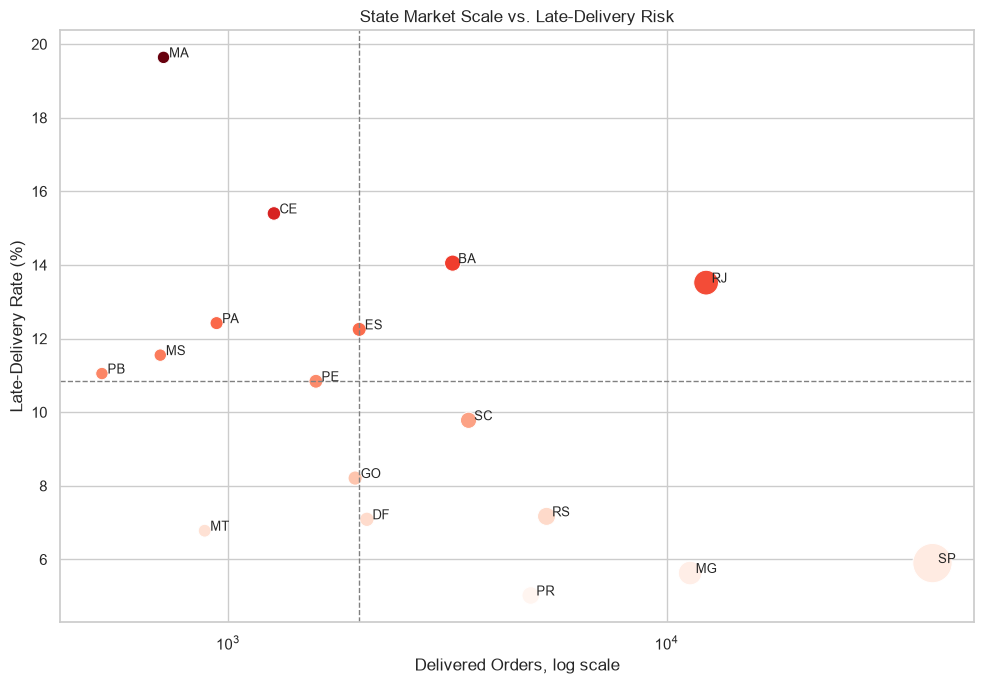

Saved to: outputs/state_scale_vs_delivery_risk.png


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=analysis_df,
    x="delivered_orders",
    y="late_delivery_rate_pct",
    size="product_revenue",
    sizes=(80, 800),
    hue="late_delivery_rate_pct",
    palette="Reds",
    legend=False,
    ax=ax
)

for _, row in analysis_df.iterrows():
    ax.text(
        row["delivered_orders"] * 1.03,
        row["late_delivery_rate_pct"],
        row["state"],
        fontsize=9
    )

median_orders = analysis_df["delivered_orders"].median()
median_delay = analysis_df["late_delivery_rate_pct"].median()

ax.axvline(
    median_orders,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axhline(
    median_delay,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_xscale("log")
ax.set_title("State Market Scale vs. Late-Delivery Risk")
ax.set_xlabel("Delivered Orders, log scale")
ax.set_ylabel("Late-Delivery Rate (%)")

plt.tight_layout()

figure_path = (
    project_root
    / "outputs"
    / "state_scale_vs_delivery_risk.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {figure_path}")

## 7. Load comparable-period scoring inputs

SQL 20 compares January-August 2017 with January-August 2018. It keeps delivered orders with actual delivery dates and states with at least 500 orders across the two windows. Order items and reviews are aggregated before joining.

In [7]:
score_sql_path = (
    project_root
    / "sql"
    / "20_state_score_inputs.sql"
)

score_query = score_sql_path.read_text(
    encoding="utf-8"
)

con = duckdb.connect(
    str(db_path),
    read_only=True
)

score_df = con.sql(score_query).df()

con.close()

print("Rows:", score_df.shape[0])
print("Columns:", score_df.shape[1])

score_df.head()

Rows: 16
Columns: 14


,state,delivered_orders,product_revenue,avg_order_value,late_orders,late_delivery_rate_pct,sellers_in_state,reviewed_orders,avg_review_score,negative_review_rate_pct,orders_2017,orders_2018,order_growth_pct,orders_per_seller
0,SP,31907,3997636.95,125.29,1925.0,6.03,1849,31741,4.25,10.59,8578.0,23329.0,171.96,17.26
1,RJ,9307,1302841.30,139.99,1096.0,11.78,171,9207,4.00,17.53,2965.0,6342.0,113.90,54.43
2,MG,8693,1172141.52,134.84,508.0,5.84,244,8639,4.19,11.97,2614.0,6079.0,132.56,35.63
3,RS,4123,552642.10,134.04,268.0,6.50,129,4112,4.22,11.02,1386.0,2737.0,97.47,31.96
4,PR,3904,534880.10,137.01,185.0,4.74,349,3887,4.27,10.37,1193.0,2711.0,127.24,11.19


## 8. Standardize the inputs

Min-max scaling maps the included states to 0-100. Reverse metrics where a lower value is preferable. This makes units comparable, but the score is sensitive to extreme values and is not a forecast. A constant column receives 50.

In [8]:
def min_max_scale(series, higher_is_better=True):
    min_value = series.min()
    max_value = series.max()

    if max_value == min_value:
        return pd.Series(50, index=series.index)

    scaled = (
        (series - min_value)
        / (max_value - min_value)
        * 100
    )

    if not higher_is_better:
        scaled = 100 - scaled

    return scaled.round(2)


standardized_df = score_df.copy()

standardized_df["scale_score"] = min_max_scale(
    standardized_df["delivered_orders"],
    higher_is_better=True
)

standardized_df["growth_score"] = min_max_scale(
    standardized_df["order_growth_pct"],
    higher_is_better=True
)

standardized_df["aov_score"] = min_max_scale(
    standardized_df["avg_order_value"],
    higher_is_better=True
)

standardized_df["satisfaction_score"] = min_max_scale(
    standardized_df["negative_review_rate_pct"],
    higher_is_better=False
)

standardized_df["delivery_risk_score"] = min_max_scale(
    standardized_df["late_delivery_rate_pct"],
    higher_is_better=True
)

standardized_df["supply_gap_score"] = min_max_scale(
    standardized_df["orders_per_seller"],
    higher_is_better=True
)

standardized_df[
    [
        "state",
        "scale_score",
        "growth_score",
        "aov_score",
        "satisfaction_score",
        "delivery_risk_score",
        "supply_gap_score",
    ]
].sort_values(
    "scale_score",
    ascending=False
)

,state,scale_score,growth_score,aov_score,satisfaction_score,delivery_risk_score,supply_gap_score
0,SP,100.00,84.00,0.00,97.11,10.73,0.85
1,RJ,27.97,36.90,22.16,6.04,58.57,6.08
2,MG,26.01,52.04,14.40,79.00,9.15,3.44
3,RS,11.45,23.58,13.19,91.47,14.64,2.92
4,PR,10.75,47.72,17.67,100.00,0.00,0.00
5,SC,7.01,44.04,29.85,67.32,41.60,0.45
6,BA,6.27,44.99,46.41,11.42,73.88,16.91
7,DF,3.41,100.00,24.15,70.60,15.06,5.94
9,ES,3.16,41.82,19.10,52.76,63.81,7.74
8,GO,3.03,50.02,30.58,66.40,23.96,3.64


## 9. Calculate the baseline score

Weights are explicit choices: scale 25%, growth 20%, order value 10%, satisfaction 20%, delivery reliability 15%, and seller coverage 10%. Seller location is only a coverage proxy. Scores reward existing coverage, not a proven supply shortage.

In [9]:
standardized_df["delivery_reliability_score"] = (
    100 - standardized_df["delivery_risk_score"]
)

standardized_df["seller_coverage_score"] = (
    100 - standardized_df["supply_gap_score"]
)

standardized_df["baseline_score"] = (
    standardized_df["scale_score"] * 0.25
    + standardized_df["growth_score"] * 0.20
    + standardized_df["aov_score"] * 0.10
    + standardized_df["satisfaction_score"] * 0.20
    + standardized_df["delivery_reliability_score"] * 0.15
    + standardized_df["seller_coverage_score"] * 0.10
).round(2)

baseline_result = standardized_df[
    [
        "state",
        "baseline_score",
        "scale_score",
        "growth_score",
        "aov_score",
        "satisfaction_score",
        "delivery_reliability_score",
        "seller_coverage_score",
    ]
].sort_values("baseline_score", ascending=False)

baseline_result

,state,baseline_score,scale_score,growth_score,aov_score,satisfaction_score,delivery_reliability_score,seller_coverage_score
0,SP,84.53,100.00,84.00,0.00,97.11,89.27,99.15
7,DF,59.53,3.41,100.00,24.15,70.60,84.94,94.06
4,PR,59.00,10.75,47.72,17.67,100.00,100.00,100.00
2,MG,57.43,26.01,52.04,14.40,79.00,90.85,96.56
13,MT,53.50,0.47,53.60,64.52,76.25,87.94,77.69
14,MS,50.01,0.09,90.19,62.84,59.06,35.11,85.87
3,RS,49.70,11.45,23.58,13.19,91.47,85.36,97.08
8,GO,48.14,3.03,50.02,30.58,66.40,76.04,96.36
5,SC,45.72,7.01,44.04,29.85,67.32,58.40,99.55
10,PE,40.36,2.16,56.44,41.91,44.88,47.34,82.66


## 10. Test alternative weights

Recalculate under growth-first and reliability-first weights. Compare ranks rather than treating score differences as statistically significant. Stable positions under these three scenarios do not prove the model is universally robust.

In [10]:
weight_sets = {
    "baseline_score": {
        "scale_score": 0.25,
        "growth_score": 0.20,
        "aov_score": 0.10,
        "satisfaction_score": 0.20,
        "delivery_reliability_score": 0.15,
        "seller_coverage_score": 0.10,
    },
    "growth_first_score": {
        "scale_score": 0.20,
        "growth_score": 0.30,
        "aov_score": 0.10,
        "satisfaction_score": 0.15,
        "delivery_reliability_score": 0.15,
        "seller_coverage_score": 0.10,
    },
    "reliability_first_score": {
        "scale_score": 0.20,
        "growth_score": 0.15,
        "aov_score": 0.10,
        "satisfaction_score": 0.20,
        "delivery_reliability_score": 0.25,
        "seller_coverage_score": 0.10,
    },
}

for score_name, weights in weight_sets.items():
    standardized_df[score_name] = sum(
        standardized_df[metric] * weight
        for metric, weight in weights.items()
    ).round(2)

comparison_df = standardized_df[
    [
        "state",
        "baseline_score",
        "growth_first_score",
        "reliability_first_score",
    ]
].copy()

for score_name in weight_sets:
    comparison_df[f"{score_name}_rank"] = (
        comparison_df[score_name]
        .rank(method="min", ascending=False)
        .astype(int)
    )

comparison_df.sort_values("baseline_score", ascending=False)

,state,baseline_score,growth_first_score,reliability_first_score,baseline_score_rank,growth_first_score_rank,reliability_first_score_rank
0,SP,84.53,83.07,84.25,1,1,1
7,DF,59.53,65.83,62.86,2,2,3
4,PR,59.00,58.23,66.08,3,3,2
2,MG,57.43,57.39,62.62,4,4,4
13,MT,53.50,55.02,59.59,5,6,5
14,MS,50.01,56.07,49.01,6,5,8
3,RS,49.70,46.92,56.49,7,8,6
8,GO,48.14,49.67,53.09,8,7,7
5,SC,45.72,46.41,49.01,9,9,8
10,PE,40.36,43.65,42.17,10,10,10


## 11. Assign recommendations and export

The rules first identify SP, then small samples, operational risk, and expansion candidates. Risk flags are separate from recommendations. The notebook retains percentage-number fields ending in _pct; the Tableau exporter converts a copy to fractional rates. No profitability or realized business impact is claimed.

In [11]:
recommendation_df = standardized_df.copy()

recommendation_df["baseline_rank"] = (
    recommendation_df["baseline_score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

def assign_recommendation(row):
    if row["state"] == "SP":
        return "Core market"

    if row["delivered_orders"] < 2000:
        return "Pilot / validate data"

    if (
        row["late_delivery_rate_pct"] >= 11
        or row["negative_review_rate_pct"] >= 16
    ):
        return "Fix operations first"

    if (
        row["baseline_rank"] <= 5
        and row["delivered_orders"] >= 3000
    ):
        return "Priority expansion"

    return "Selective expansion / monitor"


recommendation_df["recommendation"] = recommendation_df.apply(
    assign_recommendation,
    axis=1
)

final_recommendations = recommendation_df[
    [
        "state",
        "baseline_rank",
        "baseline_score",
        "delivered_orders",
        "late_delivery_rate_pct",
        "negative_review_rate_pct",
        "order_growth_pct",
        "orders_per_seller",
        "recommendation",
    ]
].sort_values("baseline_rank")

def assign_risk_flag(row):
    if (
        row["late_delivery_rate_pct"] >= 11
        or row["negative_review_rate_pct"] >= 16
    ):
        return "High operational risk"

    if row["delivered_orders"] < 2000:
        return "Limited sample"

    return "Relatively stable"


final_recommendations["risk_flag"] = final_recommendations.apply(
    assign_risk_flag,
    axis=1
)

final_recommendations = final_recommendations[
    [
        "state",
        "baseline_rank",
        "baseline_score",
        "delivered_orders",
        "late_delivery_rate_pct",
        "negative_review_rate_pct",
        "order_growth_pct",
        "orders_per_seller",
        "recommendation",
        "risk_flag",
    ]
]

output_path = project_root / "outputs" / "state_recommendations.csv"
final_recommendations.to_csv(output_path, index=False)
print(f"Saved to: {output_path}")

final_recommendations

Saved to: outputs/state_recommendations.csv


,state,baseline_rank,baseline_score,delivered_orders,late_delivery_rate_pct,negative_review_rate_pct,order_growth_pct,orders_per_seller,recommendation,risk_flag
0,SP,1,84.53,31907,6.03,10.59,171.96,17.26,Core market,Relatively stable
7,DF,2,59.53,1602,6.55,12.61,191.69,53.40,Pilot / validate data,Limited sample
4,PR,3,59.00,3904,4.74,10.37,127.24,11.19,Priority expansion,Relatively stable
2,MG,4,57.43,8693,5.84,11.97,132.56,35.63,Priority expansion,Relatively stable
13,MT,5,53.50,679,6.19,12.18,134.48,169.75,Pilot / validate data,Limited sample
14,MS,6,50.01,558,12.54,13.49,179.59,111.60,Pilot / validate data,High operational risk
3,RS,7,49.70,4123,6.50,11.02,97.47,31.96,Selective expansion / monitor,Relatively stable
8,GO,8,48.14,1482,7.62,12.93,130.07,37.05,Pilot / validate data,Limited sample
5,SC,9,45.72,2730,9.74,12.86,122.70,14.37,Selective expansion / monitor,Relatively stable
10,PE,10,40.36,1210,11.07,14.57,137.99,134.44,Pilot / validate data,High operational risk
